In [5]:
import matplotlib
import numpy as np
import pandas as pd
from narwhals import Int64
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import classification_report
from sklearn.model_selection import TunedThresholdClassifierCV, train_test_split
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, brier_score_loss)

In [6]:
train_df = pd.read_csv(r"C:\Users\maggi\CollegeSchoolWork\SDS336_MachineLearning\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0)
test_df = pd.read_csv(r"C:\Users\maggi\CollegeSchoolWork\SDS336_MachineLearning\stop-and-search\data\cleaned_data\stop_search_test1.csv", index_col=0)

In [7]:
train_df.head()

,District,Zone,StopDescription,VehicleYear,VehicleStyle,VehicleColor,SubjectID,SubjectRace,SubjectGender,SubjectAge,...,month,year,weekend,isDriver,isLA,orig_height,orig_weight,BMI,vital_flag,orig_age
FieldInterviewID,,,,,,,,,,,,,,,,,,,,,
522057,2,K,TRAFFIC VIOLATION,1998.0,FOUR DOOR,BLUE,597195,WHITE,0.0,56.0,...,9,2019,1,1,1.0,74.0,210.0,26.959459,0,56.0
464820,3,U,TRAFFIC VIOLATION,2018.0,FOUR DOOR,WHITE,529472,ASIAN,0.0,36.0,...,8,2018,0,1,1.0,66.0,150.0,24.207989,0,36.0
598110,8,C,TRAFFIC VIOLATION,2020.0,FOUR DOOR,GRAY,685380,WHITE,1.0,NaN,...,10,2022,1,0,NaN,NaN,NaN,NaN,0,NaN
456041,6,F,TRAFFIC VIOLATION,2007.0,SPORTS UTILITY,WHITE,519128,BLACK,1.0,69.0,...,6,2018,0,0,NaN,66.0,250.0,40.346648,0,69.0
584726,7,I,TRAFFIC VIOLATION,2014.0,SPORTS UTILITY,GRAY,671150,BLACK,0.0,65.0,...,6,2022,0,1,1.0,62.0,156.0,28.529657,0,65.0


# Preprocessing

In [8]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Dropping unnecessary columns for modeling
test_date = test_df["event_dt"]
test_df = test_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")
test_df["Zip"] = test_df["Zip"].astype("Int64")

# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "isLA","VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "isLA", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)
# Converting variables into strings
test_df[cat_cols] = test_df[cat_cols].astype(str)

In [9]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]
X_test = test_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_test = test_df[target]

### Classes

In [10]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

In [11]:
def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

# Modeling

In [12]:
# building pipeline using best parameters found in hyperparameter tuning script
pipeline = build_pipeline(
    RandomForestClassifier(criterion='gini', max_depth=None, min_samples_split=13, min_samples_leaf=11, max_features='log2',random_state=10), cat_cols, bin_cols, scale_cols
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

oof_probs = cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


# Calibration

### Pre-Calibration results

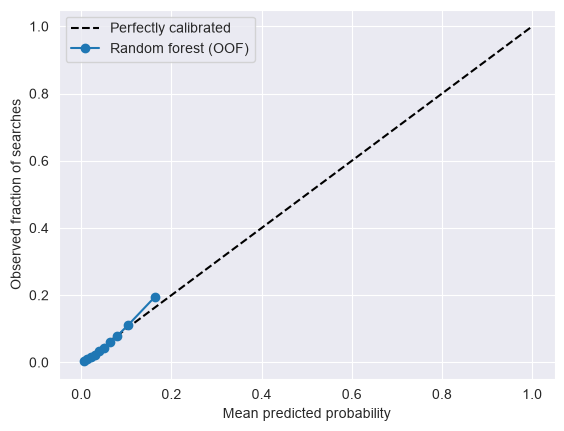

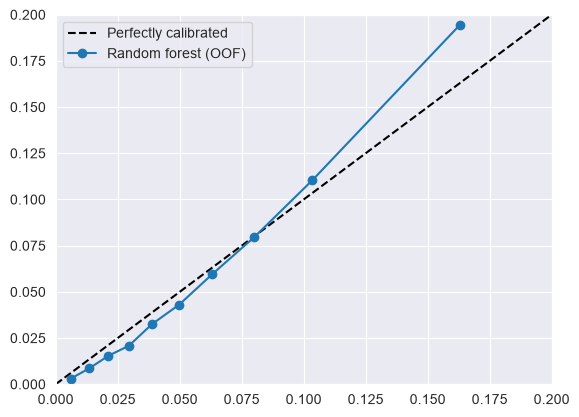

OOF Brier score: 0.05007787046803026


In [24]:
prob_true, prob_pred = calibration_curve(y_train, oof_probs, n_bins=10, strategy="quantile")

plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(prob_pred, prob_true, marker="o", label="Random forest (OOF)")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

plt.plot([0, 0.2], [0, 0.2], "k--", label="Perfectly calibrated")
plt.plot(prob_pred, prob_true, marker="o", label="Random forest (OOF)")
plt.xlim(0, 0.2); plt.ylim(0, 0.2)
plt.legend()
plt.show()

print("OOF Brier score:", brier_score_loss(y_train, oof_probs))


In [14]:
train_df['search_occurred'].value_counts()

search_occurred
0    128583
1      7738
Name: count, dtype: int64

In [15]:
bs = brier_score_loss(y_train, oof_probs)
bs_ref = brier_score_loss(y_train, np.full(len(y_train), y_train.mean()))
print("Brier skill score:", 1 - bs / bs_ref)

Brier skill score: 0.06468241543136577


### Breakdown of calibration plot by variable

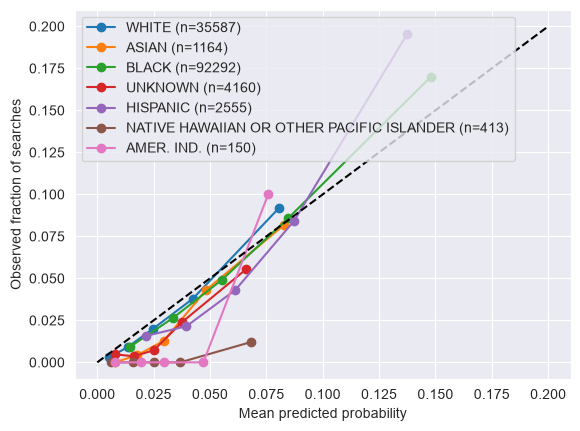

In [16]:
# SubjectRace
y_arr = y_train.to_numpy()
race = X_train["SubjectRace"].to_numpy()

for g in pd.unique(race):
    mask = race == g
    n = mask.sum()
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

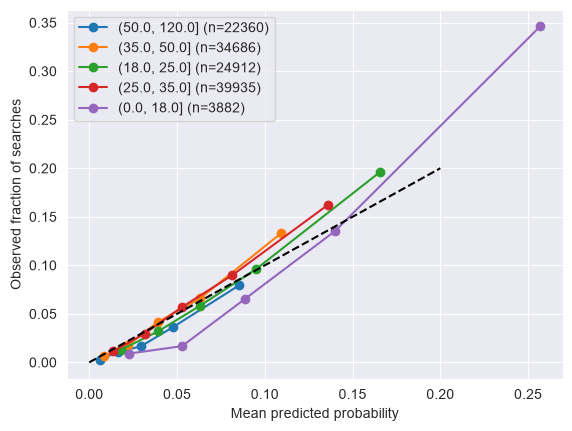

In [17]:
# SubjectAge
y_arr = y_train.to_numpy()
age_band = pd.cut(X_train["SubjectAge"], bins=[0, 18, 25, 35, 50, 120]).astype(str).to_numpy()

for g in pd.unique(age_band):
    mask = age_band == g
    n = mask.sum()
    if n < 1:   # skip tiny groups; adjust to your data
        continue
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

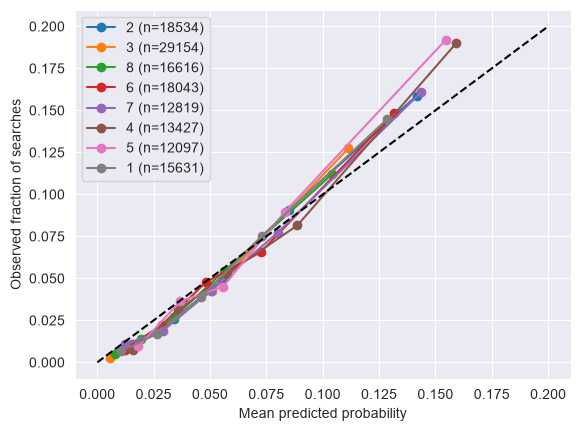

In [18]:
# District
y_arr = y_train.to_numpy()
district = X_train["District"].to_numpy()

for g in pd.unique(district):
    mask = district == g
    n = mask.sum()
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

### Calibration

In [19]:
from sklearn.isotonic import IsotonicRegression

y_arr = y_train.to_numpy()

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Platt-style (fits slope and intercept on the logit scale)
platt = cross_val_predict(LogisticRegression(C=1e6), logit(oof_probs), y_arr,
                          cv=cv, method="predict_proba")[:, 1]

# Isotonic
iso = np.zeros(len(oof_probs))
for tr, te in cv.split(oof_probs, y_arr):
    m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_probs[tr], y_arr[tr])
    iso[te] = m.predict(oof_probs[te])

ref = brier_score_loss(y_arr, np.full(len(y_arr), y_arr.mean()))
for name, p in [("raw", oof_probs), ("platt", platt), ("isotonic", iso)]:
    b = brier_score_loss(y_arr, p)
    print(name, b, "BSS:", 1 - b / ref)

raw 0.05007787046803026 BSS: 0.06468241543136577
platt 0.049885605436860686 BSS: 0.06827340008925653
isotonic 0.04989671842105328 BSS: 0.06806583995470561


Because brier scores are very similar across both recalibrations, we will use platt since it fits only two parameters, so it’s stable when positives are rare like in our dataset (~5.5% of stops), and it keeps the probabilities strictly ordered, whereas isotonic’s step function can overfit in sparse regions of the probability range

In [20]:
# Final calibrator, fit on all out-of-fold predictions, used for the test set
platt_final = LogisticRegression(C=1e6).fit(logit(oof_probs), y_arr)
print("Platt slope:", platt_final.coef_[0][0], "| intercept:", platt_final.intercept_[0])

Platt slope: 1.267008014808744 | intercept: 0.6480820785800423


# Threshold Tuning

In [26]:
tuned = TunedThresholdClassifierCV(pipeline, scoring="f1", cv=cv, thresholds=100, refit=True)
tuned.fit(X_train, y_train)

cal_thr = platt_final.predict_proba(logit(np.array([tuned.best_threshold_])))[:, 1][0]

print("Best threshold:", tuned.best_threshold_)
print("CV score at that threshold:", tuned.best_score_)
print("Calibrated threshold:", cal_thr)

KeyboardInterrupt: 

# Train on entire training set

In [25]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('bin', ...), ('imputer', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'cache_dir'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,cols,"['SubjectRace', 'Zip', ...]"
,min_freq,0.01
,fill_value,'Other'
,cat_cols,"['SubjectRace', 'Zip', ...]"
,inner,Pipeline(step...isDriver']))])


# Test Set Results

Calibrated threshold: 0.11617817172015352
Test rows: 34081 | searches: 1934 | base rate: 0.0567

--- Probability quality ---
       raw: Brier=0.04985  BSS=0.0687
calibrated: Brier=0.04966  BSS=0.0723
Calibration slope: 1.015 (ideal 1) | intercept: 0.035 (ideal 0)


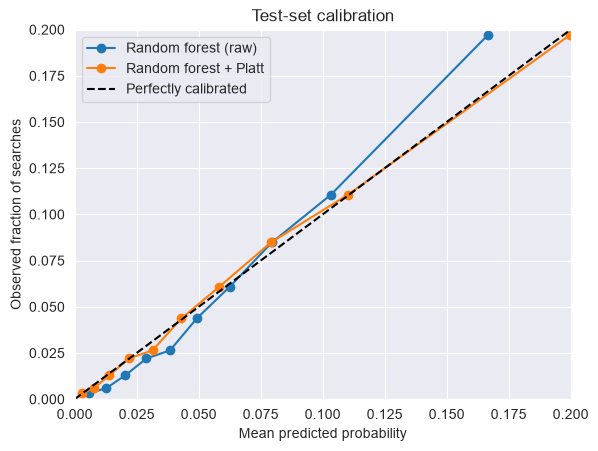


--- Ranking ---
ROC AUC: 0.7824
Average precision: 0.1918 (base rate = 0.0567)

--- Classification at tuned threshold ---
              precision    recall  f1-score   support

           0      0.962     0.885     0.922     32147
           1      0.177     0.414     0.248      1934

    accuracy                          0.858     34081
   macro avg      0.570     0.649     0.585     34081
weighted avg      0.917     0.858     0.883     34081

Confusion matrix [[TN, FP], [FN, TP]]:
 [[28437  3710]
 [ 1134   800]]
Baseline F1 (flag everyone): 0.107 | model F1: 0.248

--- race ---
group     n  observed_rate  mean_predicted    TPR    FPR  flag_rate
BLACK 23095         0.0691          0.0693 0.4690 0.1595     0.1809
WHITE  8911         0.0305          0.0284 0.1397 0.0207     0.0244


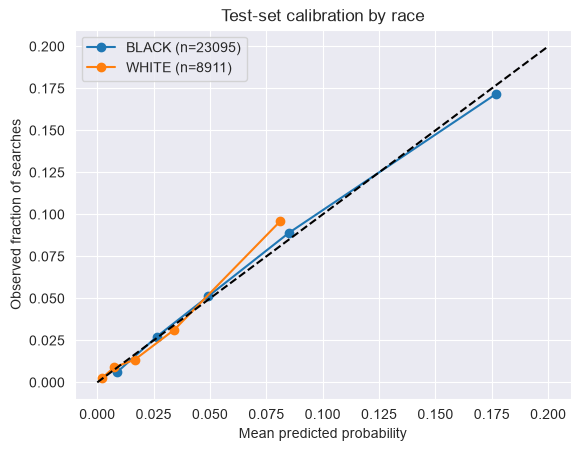


--- age band ---
        group     n  observed_rate  mean_predicted    TPR    FPR  flag_rate
 (25.0, 35.0] 10003         0.0667          0.0638 0.4333 0.1446     0.1639
 (35.0, 50.0]  8814         0.0570          0.0464 0.2430 0.0770     0.0865
 (18.0, 25.0]  6185         0.0786          0.0803 0.5391 0.2065     0.2327
(50.0, 120.0]  5542         0.0281          0.0321 0.1538 0.0212     0.0249


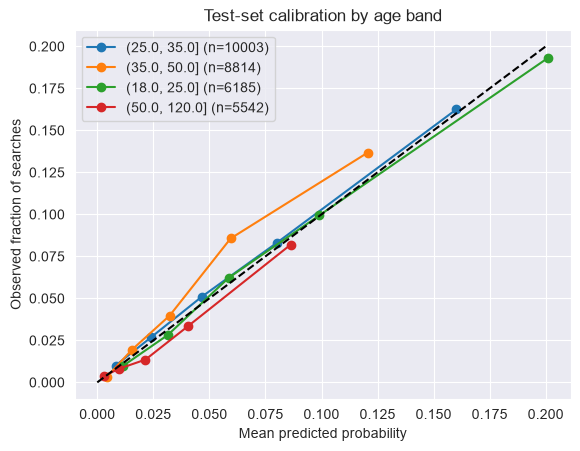


--- district ---
group    n  observed_rate  mean_predicted    TPR    FPR  flag_rate
    3 7316         0.0403          0.0388 0.3186 0.0635     0.0738
    2 4681         0.0688          0.0678 0.4348 0.1631     0.1818
    6 4576         0.0538          0.0588 0.3415 0.1185     0.1305
    8 4074         0.0452          0.0416 0.2717 0.0617     0.0712
    1 3919         0.0610          0.0565 0.3724 0.1130     0.1289
    7 3307         0.0523          0.0626 0.4682 0.1276     0.1454
    4 3234         0.0761          0.0761 0.5528 0.1851     0.2130
    5 2974         0.0770          0.0743 0.5502 0.1570     0.1873


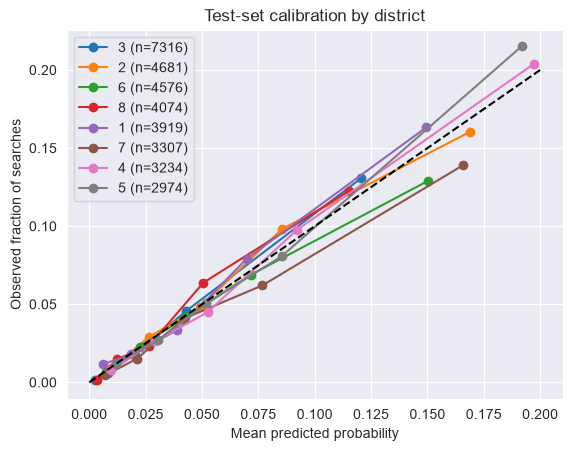

In [28]:
y_t = y_test.to_numpy()

def predict_final(X):
    raw = pipeline.predict_proba(X)[:, 1]
    cal = platt_final.predict_proba(logit(raw))[:, 1]
    return raw, cal, (cal >= cal_thr).astype(int)

test_raw, test_cal, y_pred = predict_final(X_test)
print("Calibrated threshold:", cal_thr)
print("Test rows:", len(y_t), "| searches:", y_t.sum(), f"| base rate: {y_t.mean():.4f}")

# ---------- 1. Probability quality (raw vs calibrated) ----------
ref = brier_score_loss(y_t, np.full(len(y_t), y_train.mean()))   # baseline uses TRAIN base rate
print("\n--- Probability quality ---")
for name, p in [("raw", test_raw), ("calibrated", test_cal)]:
    b = brier_score_loss(y_t, p)
    print(f"{name:>10}: Brier={b:.5f}  BSS={1 - b/ref:.4f}")

cal_fit = LogisticRegression(C=1e6).fit(logit(test_cal), y_t)
print(f"Calibration slope: {cal_fit.coef_[0][0]:.3f} (ideal 1) | "
      f"intercept: {cal_fit.intercept_[0]:.3f} (ideal 0)")

# ---------- 2. Calibration curves: raw vs calibrated ----------
plt.figure()
for name, p in [("Random forest (raw)", test_raw), ("Random forest + Platt", test_cal)]:
    pt, pp = calibration_curve(y_t, p, n_bins=10, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=name)
plt.plot([0, 0.2], [0, 0.2], "k--", label="Perfectly calibrated")
plt.xlim(0, 0.2); plt.ylim(0, 0.2)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.title("Test-set calibration")
plt.legend(); plt.show()

# ---------- 3. Ranking metrics (identical for raw and calibrated) ----------
print("\n--- Ranking ---")
print(f"ROC AUC: {roc_auc_score(y_t, test_cal):.4f}")
print(f"Average precision: {average_precision_score(y_t, test_cal):.4f} "
      f"(base rate = {y_t.mean():.4f})")

# ---------- 4. Classification at the tuned threshold ----------
print("\n--- Classification at tuned threshold ---")
print(classification_report(y_t, y_pred, digits=3))
cm = confusion_matrix(y_t, y_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

# Baseline: flag every stop as a search
f1_all = f1_score(y_t, np.ones_like(y_t))
print(f"Baseline F1 (flag everyone): {f1_all:.3f} | model F1: {f1_score(y_t, y_pred):.3f}")

# ---------- 5. Subgroup calibration and error rates ----------
MIN_N = 2000   # minimum group size; adjust and justify in the write-up

def group_table(labels, title, exclude=("nan", "<NA>")):
    rows = []
    for g in pd.unique(labels):
        if str(g) in exclude:
            continue
        m = labels == g
        n = int(m.sum())
        if n < MIN_N:
            continue
        yt, yp, pc = y_t[m], y_pred[m], test_cal[m]
        tp = int(((yp == 1) & (yt == 1)).sum()); fn = int(((yp == 0) & (yt == 1)).sum())
        fp = int(((yp == 1) & (yt == 0)).sum()); tn = int(((yp == 0) & (yt == 0)).sum())
        rows.append({
            "group": g, "n": n,
            "observed_rate": yt.mean(),
            "mean_predicted": pc.mean(),
            "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
            "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
            "flag_rate": yp.mean(),
        })
    df = pd.DataFrame(rows).sort_values("n", ascending=False)
    print(f"\n--- {title} ---")
    print(df.round(4).to_string(index=False))

    plt.figure()
    for g in df["group"]:
        m = labels == g
        pt, pp = calibration_curve(y_t[m], test_cal[m], n_bins=5, strategy="quantile")
        plt.plot(pp, pt, marker="o", label=f"{g} (n={int(m.sum())})")
    plt.plot([0, 0.2], [0, 0.2], "k--")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed fraction of searches")
    plt.title(f"Test-set calibration by {title}")
    plt.legend(); plt.show()
    return df

race = X_test["SubjectRace"].to_numpy()
age_band = pd.cut(X_test["SubjectAge"], bins=[0, 18, 25, 35, 50, 120]).astype(str).to_numpy()
district = X_test["District"].to_numpy()

race_df = group_table(race, "race")
age_df = group_table(age_band, "age band")
district_df = group_table(district, "district")